In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error
import os
import pickle
import matplotlib.pyplot as plt

os.chdir('../')
print("Current working directory:", os.getcwd())

Current working directory: c:\thesis


In [2]:
df = pd.read_csv('telemetry_data.csv')

# 1. Clean Data & Apply Penalty
# If the request was rejected, assign a huge latency penalty (e.g., 999) 
# to teach the model to avoid generating those actions.
df['outcome_latency'] = np.where(df['outcome_accepted'] == 0, 50.0, df['outcome_latency'])
df

,timestamp,sfc_type,network_active_nodes,network_free_cpu,network_free_bw,net_max_node_utilization,net_bottleneck_bw,action_max_path_distance,action_num_unique_nodes,outcome_accepted,outcome_latency
0,130.30,VoIP,0,1200.0,15000.0,0.0,1000.0,6,3,1,58.0
1,134.19,Video,3,1145.0,14800.0,20.0,940.0,4,2,1,56.0
2,199.73,Video,0,1200.0,15000.0,0.0,1000.0,7,3,1,56.0
3,212.61,Web,3,1140.0,14600.0,30.0,900.0,5,3,1,56.0
4,236.34,Web,3,1175.0,14900.0,10.0,980.0,6,3,1,52.0
...,...,...,...,...,...,...,...,...,...,...,...
20977,19996.30,VoIP,12,35.0,11410.0,100.0,320.0,0,0,0,50.0
20978,19997.14,VoIP,12,35.0,11410.0,100.0,320.0,0,0,0,50.0
20979,19997.56,VoIP,12,35.0,11410.0,100.0,320.0,0,0,0,50.0
20980,19999.32,Web,12,140.0,11690.0,100.0,360.0,4,2,1,25.0


In [3]:
# 2. Encode categorical state feature
encoder = LabelEncoder()
df['sfc_type_encoded'] = encoder.fit_transform(df['sfc_type'])

# Save the encoder mapping for the Simulator to use later
os.makedirs('models', exist_ok=True)
with open('models/label_encoder.pkl', 'wb') as f:
    pickle.dump(encoder, f)

print("Saved -> models/label_encoder.pkl")

Saved -> models/label_encoder.pkl


In [4]:
# 3. Define Features and Target
features = [
    'sfc_type_encoded', 'network_active_nodes', 'network_free_cpu', 'network_free_bw', 
    'net_max_node_utilization', 'net_bottleneck_bw', 'action_max_path_distance',
    'action_num_unique_nodes'
]
target = 'outcome_latency'

X = df[features]
y = df[target]

display(X.head())
display(y.head())

,sfc_type_encoded,network_active_nodes,network_free_cpu,network_free_bw,net_max_node_utilization,net_bottleneck_bw,action_max_path_distance,action_num_unique_nodes
0,1,0,1200.0,15000.0,0.0,1000.0,6,3
1,0,3,1145.0,14800.0,20.0,940.0,4,2
2,0,0,1200.0,15000.0,0.0,1000.0,7,3
3,2,3,1140.0,14600.0,30.0,900.0,5,3
4,2,3,1175.0,14900.0,10.0,980.0,6,3


0    58.0
1    56.0
2    56.0
3    56.0
4    52.0
Name: outcome_latency, dtype: float64

In [5]:
# 4. Train / Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Train XGBoost Knowledge Plane Model
model = xgb.XGBRegressor(
    objective='reg:squarederror', 
    n_estimators=150, 
    max_depth=5, 
    learning_rate=0.1
)
model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [6]:
# 6. Evaluate
preds = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, preds))
print(f"Model Evaluation -> Test RMSE: {rmse:.2f}")

Model Evaluation -> Test RMSE: 7.30


Text(0.5, 1.0, 'XGBoost Predictions vs Actual Latency')

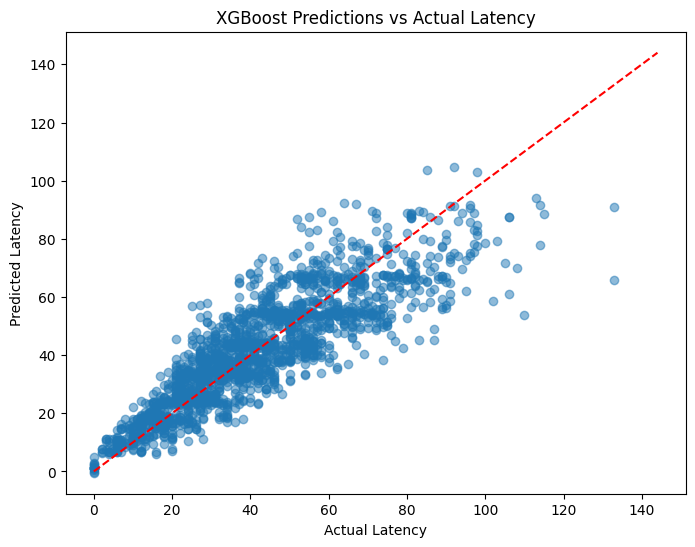

In [7]:
# 7. Plot Predictions vs Actual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, preds, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  # Line for perfect predictions
plt.xlabel('Actual Latency')
plt.ylabel('Predicted Latency')
plt.title('XGBoost Predictions vs Actual Latency')

In [8]:
# 8. Save Export the Model Target
model.save_model('models/kdn_xgboost.json')
print("Saved -> models/kdn_xgboost.json")

Saved -> models/kdn_xgboost.json
